# Active masks and ragged 3-D layers on a real flood mesh

Hydrodynamic mesh results carry two kinds of structure a plain `(time, layer, element)` block
cannot hold faithfully, and `UgridDataset` now models both (additively — a 2-D or uniform mesh
behaves exactly as before):

1. **A per-timestep active (wet/dry) mask** — a cell can be *wet* at one step and *dry* at the
   next; folding "dry" into `NaN` loses the distinction between a dry cell and a missing one.
2. **Ragged per-column vertical layers** — a genuinely 3-D column carries a different number of
   active layers than its neighbour, so the data is a flat `volume` axis, not a rectangular
   `(layer, face)` block.

This tutorial uses a **real D-Flow FM flood simulation** — the *Manzese* test case from the
[MDAL](https://github.com/lutraconsulting/MDAL) project (Lutra Consulting, MIT-licensed;
`tests/data/ugrid/D-Flow1.1/manzese_1d2d_small_map.nc`). We kept its unstructured `mesh2d`
(1 824 faces) and its real `waterdepth` / water-level (`s1`) fields over 6 output steps, and
rewrote that subset through pyramids' own UGRID writer so the sample is small and self-contained.

In [1]:
%matplotlib inline
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pyramids.netcdf.ugrid import UgridDataset, VolumeTopology
from pyramids.plot import ColorBar

# Notebook-relative path (the kernel's working directory is this notebook's folder).
DATA = Path("../../../../examples/data/ugrid/manzese_flood_mesh2d.nc")

ds = UgridDataset.read_file(DATA)
print("mesh :", ds.mesh_name, "| nodes:", ds.n_node, "faces:", ds.n_face)
print("vars :", ds.data_variable_names)
depth = ds["mesh2d_waterdepth"]
print(
    "waterdepth:",
    depth.shape,
    "dims",
    depth.dimensions,
    "range",
    round(float(np.nanmin(depth.data)), 2),
    "..",
    round(float(np.nanmax(depth.data)), 2),
)

mesh : mesh2d | nodes: 3042 faces: 1824
vars : ['mesh2d_s1', 'mesh2d_waterdepth']
waterdepth: (6, 1824) dims ('time', 'mesh2d_nFaces') range 0.0 .. 1.0


## The flood front

The simulation floods the domain over its six steps: the wet area grows from ~1 % of the cells
to ~15 %. We plot the water depth at the first and last step — the dry cells (depth 0) are the
white background the water spreads across.

/tmp/ipykernel_3774/245703939.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


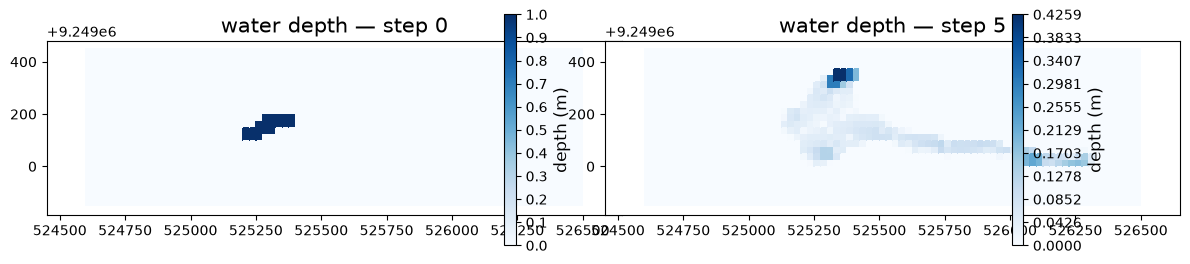

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, step in zip(axes, (0, ds["mesh2d_waterdepth"].n_time_steps - 1)):
    ds.isel(time=step).plot(
        "mesh2d_waterdepth",
        ax=ax,
        cmap="Blues",
        title=f"water depth — step {step}",
        colorbar=ColorBar(label="depth (m)"),
    )
plt.tight_layout()
plt.show()

## Part 1 — a first-class wet/dry mask (issue #1331)

A cell is *wet* where its water depth exceeds a small drying threshold. That is a per-step
boolean, distinct from "missing": a dry cell has a perfectly good value (depth ≈ 0), it is simply
not part of the active flow. We derive the mask from the **real** depths and attach it to the
variable through its first-class `active` field.

In [3]:
DRYING = 0.01  # metres; below this a D-Flow FM cell is treated as dry
depths = np.asarray(ds["mesh2d_waterdepth"].data)
wet = depths > DRYING  # (n_time, n_face) boolean — a per-step mask

# `active` is a first-class field on the variable; set it in place.
ds["mesh2d_waterdepth"].active = wet

mask = ds.active_mask("mesh2d_waterdepth")
print("mask shape:", mask.shape, "(per-step: n_time x n_face)")
print("wet cells per step:", [int(w.sum()) for w in mask])

mask shape: (6, 1824) (per-step: n_time x n_face)
wet cells per step: [19, 143, 170, 185, 197, 207]


`active_mask` hands back the raw boolean field — it is **never** applied to the values on its
own. `masked_values` is the opt-in: it blanks dry cells to `NaN` *in addition to* the usual
no-data blanking, so a caller who wants "treat dry as missing" asks for it explicitly, while the
two stay distinguishable.

In [4]:
masked = ds.masked_values("mesh2d_waterdepth")  # dry -> NaN, on demand
raw = np.asarray(ds["mesh2d_waterdepth"].data)  # the untouched values
last = raw.shape[0] - 1
print("dry cells blanked at last step:", int(np.isnan(masked[last]).sum()))
print("same cells in the raw data are not NaN:", not np.isnan(raw[last]).any())
print(
    "a dry cell keeps its real value in .data:",
    float(raw[last][~wet[last]][0]),
    "-> NaN in masked_values:",
    float(masked[last][~wet[last]][0]),
)

dry cells blanked at last step: 1617
same cells in the raw data are not NaN: True
a dry cell keeps its real value in .data: 0.0 -> NaN in masked_values: nan


### The mask unlocks a wetted-area time series

Because the mask is kept per step and separate from the values, we can measure the **wetted
area** — the real reason to keep wet/dry rather than fold it into `NaN`. We weight each wet cell
by its real face area.

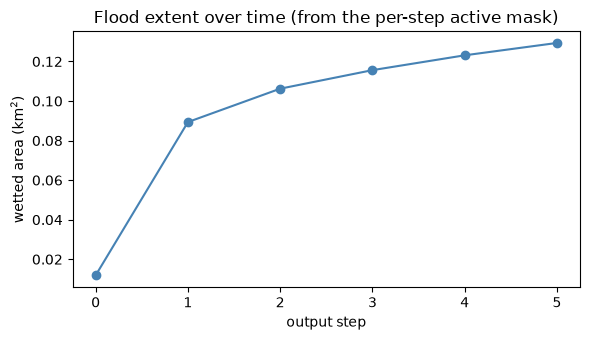

wetted area per step (km^2): [0.012, 0.089, 0.106, 0.116, 0.123, 0.129]


In [5]:
areas = ds.mesh.face_areas  # m^2 per face, from the real geometry
wetted_area = np.array([areas[w].sum() for w in wet])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(len(wetted_area)), wetted_area / 1e6, "o-", color="steelblue")
ax.set_xlabel("output step")
ax.set_ylabel("wetted area (km$^2$)")
ax.set_title("Flood extent over time (from the per-step active mask)")
plt.tight_layout()
plt.show()
print("wetted area per step (km^2):", [round(float(a) / 1e6, 3) for a in wetted_area])

### The mask rides through selections and round-trips to disk

Selecting a step or a range slices the mask with the data, and writing the mesh to NetCDF keeps
the mask as a companion variable — distinct from the fill value — so a read brings it back.

In [6]:
one = ds.isel(time=last)  # collapse to the last step
print("after isel(time): mask ->", one.active_mask("mesh2d_waterdepth").shape)
rng = ds.sel_time_range(1, 4)
print("after sel_time_range(1, 4): mask ->", rng.active_mask("mesh2d_waterdepth").shape)

with tempfile.TemporaryDirectory() as tmp:
    out = Path(tmp) / "manzese_masked.nc"
    ds.to_file(out)
    back = UgridDataset.read_file(out)
    rt = back.active_mask("mesh2d_waterdepth")
    print(
        "round-trip mask preserved:",
        rt is not None,
        "| identical:",
        bool((rt == wet).all()),
    )
    print(
        "the main variable now advertises its mask companion:",
        back["mesh2d_waterdepth"].attributes.get("ancillary_variables"),
    )

after isel(time): mask -> (1824,)
after sel_time_range(1, 4): mask -> (3, 1824)
round-trip mask preserved: True | identical: True
the main variable now advertises its mask companion: mesh2d_waterdepth_active


## Part 2 — ragged per-column vertical layers (issue #1330)

pyramids' built-in reader is 2-D: a genuinely 3-D file's layers are read by a `pyramids-mesh`
driver plugin. Here we **construct** a `VolumeTopology` on this real mesh to show the model and
its accessors — deeper flooded columns get more sigma layers, shallow ones fewer, so the layering
is *ragged*. (A real 3-D driver populates the same object from the file's own vertical grid.)

In [7]:
# Work with the wettest step so the column depths are meaningful; every face gets at least one
# layer, deeper water gets more (clamped to 6). This is a CSR layout: offsets into a flat volume
# axis, one slice per column.
d_last = depths[last]
layer_count = np.clip(1 + np.rint(d_last / 0.2).astype(int), 1, 6)
volume_offset = np.concatenate([[0], np.cumsum(layer_count)])
topology = VolumeTopology(layer_count=layer_count, volume_offset=volume_offset)
print(
    "faces:",
    topology.n_face,
    "| volumes:",
    topology.n_volume,
    "| deepest column has",
    topology.max_layers,
    "layers",
)

# A flat (n_volume,) "salinity" that decays with layer position within each column.
layer_pos = topology.layer_of_volume()
salinity = 35.0 - 0.5 * layer_pos
vol_var = ds["mesh2d_waterdepth"].with_data(salinity)  # reuse mesh/location plumbing
vol_var.location = "volume"
vol_var.dimensions = ("mesh2d_nVolumes",)
vol_var.active = None
vol3d = UgridDataset(ds.mesh, {"salinity": vol_var}, {}, volume_topology=topology)
print("n_volume:", vol3d.n_volume, "| n_layers (max over columns):", vol3d.n_layers)

faces: 1824 | volumes: 1870 | deepest column has 3 layers
n_volume: 1870 | n_layers (max over columns): 3


`isel_layer(k)` takes the k-th layer **per column**, as a plain 2-D face field. A column that is
shallower than `k + 1` layers has no such layer, so it comes back `NaN` — never silently padded.

In [8]:
surface = vol3d.isel_layer(0)["salinity"]  # layer 0 exists in every column
deep = vol3d.isel_layer(4)["salinity"]  # only columns with >=5 layers have it
print("surface layer -> location:", surface.location, "shape:", surface.data.shape)
print(
    "columns present at layer 4:",
    int(np.isfinite(deep.data).sum()),
    "of",
    topology.n_face,
    "(rest are NaN, not padded)",
)

# `collapse_layer` is the same operation under a name that says 'give me a 2-D slice'.
bed_slice = vol3d.collapse_layer(0)["salinity"]
print(
    "collapse_layer(0) matches isel_layer(0):",
    bool((bed_slice.data == surface.data).all()),
)

surface layer -> location: face shape: (1824,)
columns present at layer 4: 0 of 1824 (rest are NaN, not padded)
collapse_layer(0) matches isel_layer(0): True


The tidy frame lays a ragged variable out **one row per volume**, carrying the column (`element`)
and the 0-based `layer` within it — no row is fabricated for a layer a column does not have. And
the whole topology round-trips through NetCDF.

In [9]:
frame = vol3d.to_dataframe()
print("tidy rows:", len(frame), "== n_volume:", vol3d.n_volume)
print(frame[["variable", "element", "layer", "value"]].head(8).to_string(index=False))

with tempfile.TemporaryDirectory() as tmp:
    out = Path(tmp) / "manzese_3d.nc"
    vol3d.to_file(out)
    back = UgridDataset.read_file(out)
    vt = back.volume_topology
    print(
        "round-trip topology preserved:",
        vt is not None,
        "| same layer counts:",
        bool((vt.layer_count == layer_count).all()),
        "| same n_volume:",
        vt.n_volume == topology.n_volume,
    )

tidy rows: 1870 == n_volume: 1870
variable  element  layer  value
salinity        0      0   35.0
salinity        1      0   35.0
salinity        2      0   35.0
salinity        3      0   35.0
salinity        4      0   35.0
salinity        5      0   35.0
salinity        6      0   35.0
salinity        7      0   35.0
round-trip topology preserved: True | same layer counts: True | same n_volume: True


## Summary

- The **active mask** (`MeshVariable.active`, `UgridDataset.active_mask` / `masked_values`) keeps
  per-step wet/dry status first-class and separate from `nodata`, so "dry" never masquerades as
  "missing" and quantities like a wetted-area time series stay recoverable. It rides through the
  shape-preserving selections and round-trips to NetCDF and xarray.
- The **ragged volume topology** (`VolumeTopology`, `location="volume"`, `isel_layer` /
  `collapse_layer` / `n_volume`) represents genuinely 3-D columns with different layer counts
  without padding, and makes absent layers explicit.

Both are additive — a 2-D or uniform-layer mesh is unaffected. See the reference page
*3-D results (masks & ragged layers)* for the on-disk layout, and issues #1331 and #1330.